<a href="https://colab.research.google.com/github/ali-akbar-bermano/Lecture-series_ALI-AKBAR-BERMANO_G1A024041/blob/main/implementasi_lecture_series_pertemuan_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Perancangan & Evaluasi Dashboard Interaktif Evaluasi Usability (HCI & Data Visualization)**

1. Import Library & Setup Environment

In [1]:
# SEL 1: IMPORT MODULES & LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as gg

print("✅ Sel 1: Pustaka analisis data dan visualisasi interaktif berhasil dimuat!")

✅ Sel 1: Pustaka analisis data dan visualisasi interaktif berhasil dimuat!


2. Dataset Generation (Usability Testing & User Persona Metrics)

In [2]:
# SEL 2: GENERASI / LOADING DATASET USABILITY TESTING
def load_usability_testing_data(n_users=150, random_state=42):
    np.random.seed(random_state)

    # Kategori Profil User Persona (Sesuai Materi Sesi HCI)
    personas = np.random.choice(['Lansia (Nenek Sumaria)', 'Profesional (Pak Edi)', 'Gen-Z (Bagus)'],
                                size=n_users, p=[0.25, 0.45, 0.30])

    # Metrik Pengujian Usability
    task_completion_time = [] # dalam detik
    error_count = []          # jumlah kesalahan klik/input
    sus_score = []            # Skor System Usability Scale (0-100)
    task_status = []          # Success / Fail

    for p in personas:
        if p == 'Lansia (Nenek Sumaria)':
            time = np.random.normal(45, 10)
            err = np.random.poisson(3.5)
            sus = np.random.normal(62, 8)
            status = np.random.choice(['Success', 'Fail'], p=[0.75, 0.25])
        elif p == 'Profesional (Pak Edi)':
            time = np.random.normal(18, 4)
            err = np.random.poisson(0.8)
            sus = np.random.normal(84, 6)
            status = np.random.choice(['Success', 'Fail'], p=[0.95, 0.05])
        else: # Gen-Z (Bagus)
            time = np.random.normal(12, 3)
            err = np.random.poisson(1.2)
            sus = np.random.normal(88, 5)
            status = np.random.choice(['Success', 'Fail'], p=[0.98, 0.02])

        task_completion_time.append(max(5, round(time, 1)))
        error_count.append(max(0, err))
        sus_score.append(min(100, max(20, round(sus, 1))))
        task_status.append(status)

    df = pd.DataFrame({
        'User_ID': [f'USR-{i+1:03d}' for i in range(n_users)],
        'User_Persona': personas,
        'Task_Time_Sec': task_completion_time,
        'Error_Count': error_count,
        'SUS_Score': sus_score,
        'Task_Status': task_status
    })
    return df

# Memuat dataset ke DataFrame
df_usability = load_usability_testing_data()
print("✅ Sel 2: Dataset Usability Testing berhasil dibuat!")
print(f"Total Sampel Pengguna: {len(df_usability)} Penguji\n")
print(df_usability.head())

✅ Sel 2: Dataset Usability Testing berhasil dibuat!
Total Sampel Pengguna: 150 Penguji

   User_ID            User_Persona  Task_Time_Sec  Error_Count  SUS_Score  \
0  USR-001   Profesional (Pak Edi)           17.2            0       85.8   
1  USR-002           Gen-Z (Bagus)           15.4            0       91.8   
2  USR-003           Gen-Z (Bagus)           16.2            2       81.0   
3  USR-004   Profesional (Pak Edi)           14.0            0       80.6   
4  USR-005  Lansia (Nenek Sumaria)           29.5            3       62.5   

  Task_Status  
0     Success  
1     Success  
2     Success  
3     Success  
4        Fail  


3. Metrik Ringkasan Usability (Overview First)

In [3]:
# SEL 3: KALKULASI METRIK RINGKASAN MAKRO (OVERVIEW METRICS)
def calculate_usability_kpis(df):
    total_users = len(df)
    avg_sus = round(df['SUS_Score'].mean(), 1)
    avg_time = round(df['Task_Time_Sec'].mean(), 1)
    success_rate = round((df['Task_Status'] == 'Success').sum() / total_users * 100, 1)
    avg_errors = round(df['Error_Count'].mean(), 2)

    print("="*45)
    print(" 📊 METRIK UTAMA EVALUASI USABILITY DASHBOARD")
    print("="*45)
    print(f" • Total Penguji (Users)       : {total_users} orang")
    print(f" • Rata-rata Skor SUS          : {avg_sus} / 100")
    print(f" • Tingkat Keberhasilan Tasks  : {success_rate}%")
    print(f" • Rata-rata Waktu Tugas       : {avg_time} detik")
    print(f" • Rata-rata Jumlah Kesalahan  : {avg_errors} errors/task")
    print("="*45 + "\n")

calculate_usability_kpis(df_usability)

 📊 METRIK UTAMA EVALUASI USABILITY DASHBOARD
 • Total Penguji (Users)       : 150 orang
 • Rata-rata Skor SUS          : 78.8 / 100
 • Tingkat Keberhasilan Tasks  : 88.0%
 • Rata-rata Waktu Tugas       : 23.6 detik
 • Rata-rata Jumlah Kesalahan  : 1.67 errors/task



4. Analisis Distribusi Persona & Beban Kognitif (Edward Tufte Principles)

/tmp/ipykernel_4239/1777235659.py:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='User_Persona', y='SUS_Score', ax=axes[0], palette='Blues_d', ci=None)
/tmp/ipykernel_4239/1777235659.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='User_Persona', y='SUS_Score', ax=axes[0], palette='Blues_d', ci=None)
/tmp/ipykernel_4239/1777235659.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='User_Persona', y='Task_Time_Sec', ax=axes[1], palette='Set2')


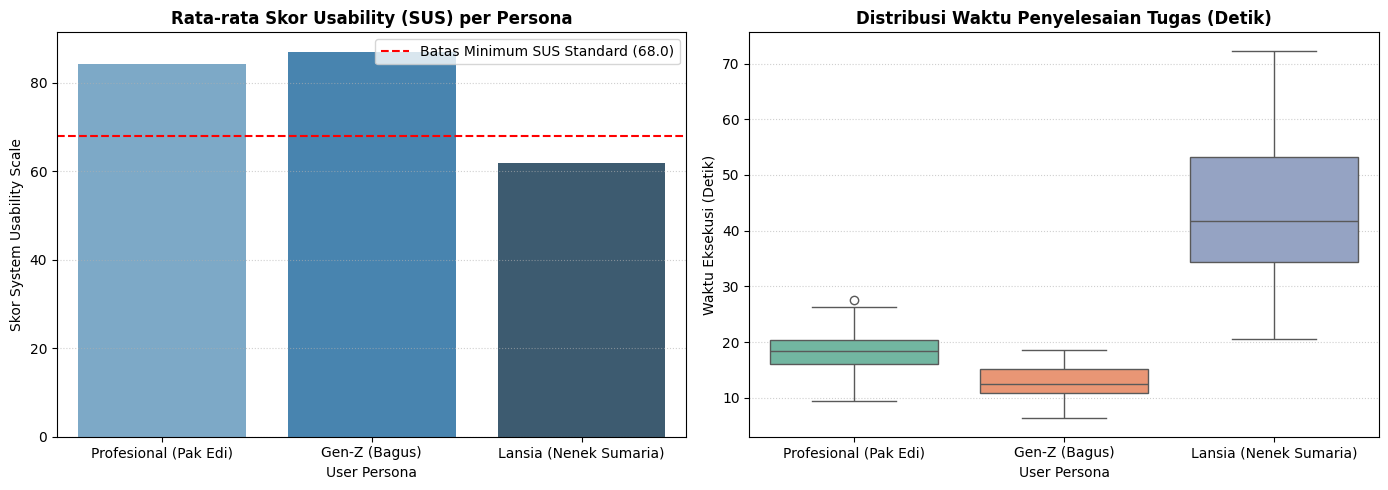

In [4]:
# SEL 4: VISUALISASI DISTRIBUSI PENGGUNA & KESALAHAN INTERAKSI
def plot_persona_cognitive_load(df):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Bar Chart: Rata-rata Skor SUS per User Persona (Sesuai Prinsip Tufte - Tanpa Hiasan Berlebih)
    sns.barplot(data=df, x='User_Persona', y='SUS_Score', ax=axes[0], palette='Blues_d', ci=None)
    axes[0].axhline(68, color='red', linestyle='--', label='Batas Minimum SUS Standard (68.0)')
    axes[0].set_title('Rata-rata Skor Usability (SUS) per Persona', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('User Persona')
    axes[0].set_ylabel('Skor System Usability Scale')
    axes[0].legend()
    axes[0].grid(axis='y', linestyle=':', alpha=0.6)

    # 2. Box Plot: Distribusi Waktu Penyelesaian Tugas (Deteksi Usability Friction)
    sns.boxplot(data=df, x='User_Persona', y='Task_Time_Sec', ax=axes[1], palette='Set2')
    axes[1].set_title('Distribusi Waktu Penyelesaian Tugas (Detik)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('User Persona')
    axes[1].set_ylabel('Waktu Eksekusi (Detik)')
    axes[1].grid(axis='y', linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

plot_persona_cognitive_load(df_usability)

5. Interactive Visual Dashboard Engine (Shneiderman’s Taxonomy)

In [5]:
# SEL 5: INTERACTIVE DASHBOARD DENGAN PLOTLY (ZOOM, FILTER, DETAILS-ON-DEMAND)
def create_interactive_usability_dashboard(df):
    # Scatter Plot Interaktif: Korelasi Waktu vs Skor SUS dengan Detail Hover (Details-on-Demand)
    fig = px.scatter(
        df,
        x='Task_Time_Sec',
        y='SUS_Score',
        color='User_Persona',
        size='Error_Count',
        symbol='Task_Status',
        hover_data=['User_ID', 'Error_Count'],
        title="<b>Interactive Dashboard: Korelasi Waktu Tugas vs Skor SUS per Persona</b><br><sup>(Ukuran Gelembung = Jumlah Kesalahan Klik / Error)</sup>",
        labels={
            'Task_Time_Sec': 'Waktu Penyelesaian Tugas (Detik)',
            'SUS_Score': 'Skor System Usability Scale (SUS)',
            'User_Persona': 'User Persona'
        },
        template='plotly_white'
    )

    # Garis Batas Ambang Standar Usability
    fig.add_hline(y=68, line_dash="dash", line_color="red", annotation_text="Standar Kelayakan SUS (68)")

    fig.update_layout(
        font_family="Arial",
        legend_title_text="Persona Pengguna",
        hoverlabel=dict(bgcolor="white", font_size=12)
    )

    return fig

print("✅ Sel 5: Fungsi pembuat dashboard interaktif siap dieksekusi!")

✅ Sel 5: Fungsi pembuat dashboard interaktif siap dieksekusi!


6. Display Interactive Dashboard

In [6]:
# SEL 6: EKSEKUSI & TAMPILKAN DASHBOARD INTERAKTIF
dashboard_fig = create_interactive_usability_dashboard(df_usability)

# Menampilkan Dashboard di Colab
dashboard_fig.show()